# Banana Leaf Disease Classifier (BananaLSD)
EfficientNetB0 transfer learning · **OriginalSet only** (no augmented-set leakage) · stratified split · 2-stage fine-tuning · TTA

**Runtime → Change runtime type → T4 GPU**, then run all cells.

## 1. Setup

In [1]:
import os, glob, shutil, hashlib, random, zipfile, json
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Upload the dataset zip from your device & extract OriginalSet only

In [2]:
from google.colab import files

EXTRACT_TO = "/content/data"
CLASS_NAMES = {"cordana", "healthy", "pestalotiopsis", "sigatoka"}

# --- pick the uploaded zip (re-use one already in /content, else open upload dialog) ---
zips = [z for z in glob.glob("/content/*.zip") if os.path.getsize(z) > 5e6]
if not zips:
    up = files.upload()
    zips = [f"/content/{n}" for n in up if n.lower().endswith(".zip")]
assert zips, "No valid zip found. Upload the BananaLSD dataset zip."
ZIP_PATH = max(zips, key=os.path.getsize)
print(f"Zip: {os.path.basename(ZIP_PATH)} ({os.path.getsize(ZIP_PATH)/1e6:.1f} MB)")

# --- what does the zip contain? ---
with zipfile.ZipFile(ZIP_PATH) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]
sets = {}
for n in names:
    low = n.lower()
    key = "augmented" if "augment" in low else ("original" if "original" in low else "other")
    sets[key] = sets.get(key, 0) + 1
print("Files in zip by set:", sets)
assert sets.get("original", 0) > 0, (
    "This zip has no OriginalSet folder. Zip the OriginalSet folder from your PC and upload that instead.")

# --- extract ONLY original files (augmented is never touched) ---
shutil.rmtree(EXTRACT_TO, ignore_errors=True)
os.makedirs(EXTRACT_TO, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    members = [m for m in z.namelist() if "augment" not in m.lower() and "original" in m.lower()]
    z.extractall(EXTRACT_TO, members)

# --- find the folder that directly holds the 4 class folders ---
cands = []
for d in glob.glob(f"{EXTRACT_TO}/**/", recursive=True):
    d = d.rstrip("/")
    subs = {s.lower() for s in os.listdir(d) if os.path.isdir(os.path.join(d, s))}
    if CLASS_NAMES <= subs and "augment" not in d.lower():
        cands.append(d)
assert cands, "Could not find the 4 class folders inside OriginalSet - paste the output of the listing below."
DATA_DIR = cands[0]
print("\nUsing:", DATA_DIR)
for c in sorted(os.listdir(DATA_DIR)):
    print(f"  {c:16s} {len(os.listdir(os.path.join(DATA_DIR, c)))}")

Saving Banana Leaf Spot Diseases (BananaLSD) Dataset for Classification of Banana Leaf Diseases Using Machine Learning.zip to Banana Leaf Spot Diseases (BananaLSD) Dataset for Classification of Banana Leaf Diseases Using Machine Learning.zip
Zip: Banana Leaf Spot Diseases (BananaLSD) Dataset for Classification of Banana Leaf Diseases Using Machine Learning.zip (54.5 MB)
Files in zip by set: {'augmented': 1600, 'original': 937}

Using: /content/data/Banana Leaf Spot Diseases (BananaLSD) Dataset for Classification of Banana Leaf Diseases Using Machine Learning/BananaLSD/OriginalSet
  cordana          162
  healthy          129
  pestalotiopsis   173
  sigatoka         473


## 3. File list, duplicate removal, stratified split (70/15/15)

In [3]:
CLASSES = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
print("Classes:", CLASSES)

rows = []
for c in CLASSES:
    for f in glob.glob(os.path.join(DATA_DIR, c, "*")):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((f, class_to_idx[c]))
df = pd.DataFrame(rows, columns=["path", "label"])

# drop exact duplicate files so one photo can't land in both train and test
df["md5"] = df.path.map(lambda p: hashlib.md5(open(p, "rb").read()).hexdigest())
before = len(df)
df = df.drop_duplicates("md5").reset_index(drop=True)
print(f"Images: {before} -> {len(df)} after removing exact duplicates")
print(df.label.map(lambda i: CLASSES[i]).value_counts())

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
print("train/val/test:", len(train_df), len(val_df), len(test_df))

# class weights (Sigatoka has far more images)
counts = np.bincount(train_df.label, minlength=len(CLASSES))
cw = (counts.sum() / (len(CLASSES) * counts)).astype("float32")
print("Class weights:", dict(zip(CLASSES, cw.round(2))))

Classes: ['cordana', 'healthy', 'pestalotiopsis', 'sigatoka']
Images: 937 -> 898 after removing exact duplicates
label
sigatoka          473
pestalotiopsis    172
cordana           162
healthy            91
Name: count, dtype: int64
train/val/test: 628 135 135
Class weights: {'cordana': np.float32(1.39), 'healthy': np.float32(2.45), 'pestalotiopsis': np.float32(1.31), 'sigatoka': np.float32(0.47)}


## 4. Input pipeline (augmentation on TRAIN only)

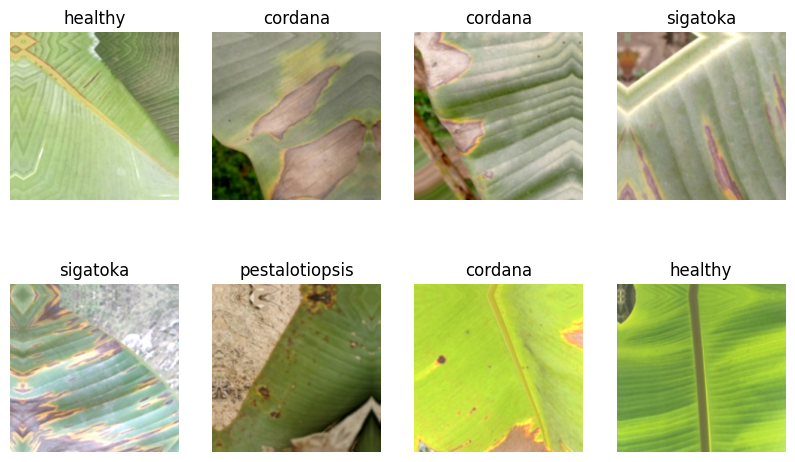

In [4]:
IMG = 224
BATCH = 32
NUM_CLASSES = len(CLASSES)
cw_tensor = tf.constant(cw)

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG, IMG))            # EfficientNet expects 0-255 floats
    return img, tf.one_hot(label, NUM_CLASSES), tf.gather(cw_tensor, label)

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="augment")

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values.astype("int32")))
    if train:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)
    if train:
        ds = ds.map(lambda x, y, w: (augment(x, training=True), y, w), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

x, y, _ = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(CLASSES[int(tf.argmax(y[i]))]); plt.axis("off")
plt.show()

## 5. Model: EfficientNetB0 (ImageNet pretrained)

In [5]:
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False

inputs = keras.Input((IMG, IMG, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

loss = keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss, metrics=["accuracy"])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

## 6. Stage 1 – train the head

In [6]:
def cbs(path):
    return [
        keras.callbacks.ModelCheckpoint(path, monitor="val_accuracy", save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1),
    ]

h1 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cbs("stage1.keras"))

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5324 - loss: 1.6811   
Epoch 1: val_accuracy improved from None to 0.85926, saving model to stage1.keras

Epoch 1: finished saving model to stage1.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.6704 - loss: 1.3181 - val_accuracy: 0.8593 - val_loss: 0.8264 - learning_rate: 0.0010
Epoch 2/20
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.8185 - loss: 0.9840
Epoch 2: val_accuracy improved from 0.85926 to 0.91111, saving model to stage1.keras

Epoch 2: finished saving model to stage1.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 452ms/step - accuracy: 0.8551 - loss: 0.9438 - val_accuracy: 0.9111 - val_loss: 0.7439 - learning_rate: 0.0010
Epoch 3/20
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.8481 - loss: 0.9794
Epoch 3: val_accuracy did not improve from 0.91111
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 408ms/step - accuracy: 0.8567 - loss: 0.8763 - val_accuracy: 0.9037 - val_loss: 0.7499 - learning_rate: 0.0010
Epoch 

## 7. Stage 2 – fine-tune the top of the backbone (low LR, BatchNorm frozen)

Epoch 1/40
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9111 - loss: 0.7288   
Epoch 1: val_accuracy improved from None to 0.96296, saving model to best_banana_model.keras

Epoch 1: finished saving model to best_banana_model.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.9188 - loss: 0.6668 - val_accuracy: 0.9630 - val_loss: 0.6266 - learning_rate: 1.0000e-05
Epoch 2/40
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.9153 - loss: 0.6627
Epoch 2: val_accuracy did not improve from 0.96296
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 407ms/step - accuracy: 0.9156 - loss: 0.6830 - val_accuracy: 0.9630 - val_loss: 0.6306 - learning_rate: 1.0000e-05
Epoch 3/40
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.9336 - loss: 0.6385
Epoch 3: val_accuracy did not improve from 0.96296
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 406ms/step - accuracy: 0.9347 - loss: 0.6446 - val_accuracy: 0.9630 - val_loss: 0.6333 - learning_rate: 1.0000e-05
Epoch 4/40
19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - a

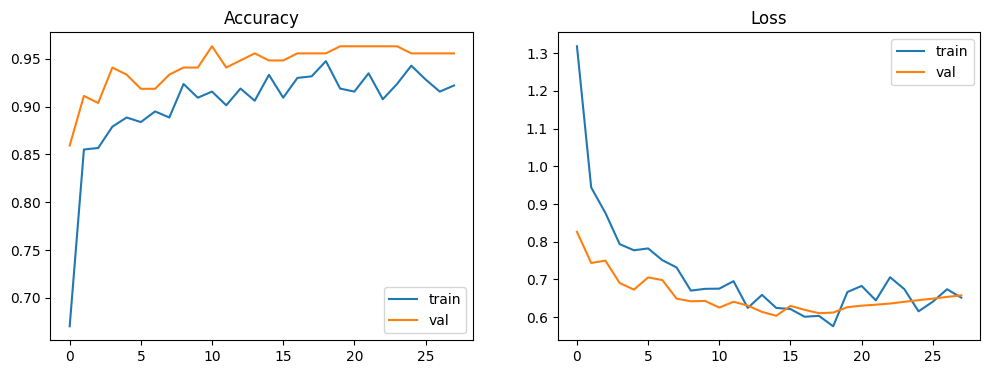

In [7]:
base.trainable = True
for l in base.layers[:-40]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss=loss, metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=cbs("best_banana_model.keras"))

acc = h1.history["accuracy"] + h2.history["accuracy"]; vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
ls = h1.history["loss"] + h2.history["loss"]; vls = h1.history["val_loss"] + h2.history["val_loss"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(ls, label="train"); ax[1].plot(vls, label="val"); ax[1].set_title("Loss"); ax[1].legend()
plt.show()

## 8. Final test-set evaluation (flip TTA)

Test accuracy: 0.9852
                precision    recall  f1-score   support

       cordana     0.9600    0.9600    0.9600        25
       healthy     1.0000    1.0000    1.0000        13
pestalotiopsis     0.9630    1.0000    0.9811        26
      sigatoka     1.0000    0.9859    0.9929        71

      accuracy                         0.9852       135
     macro avg     0.9807    0.9865    0.9835       135
  weighted avg     0.9855    0.9852    0.9852       135



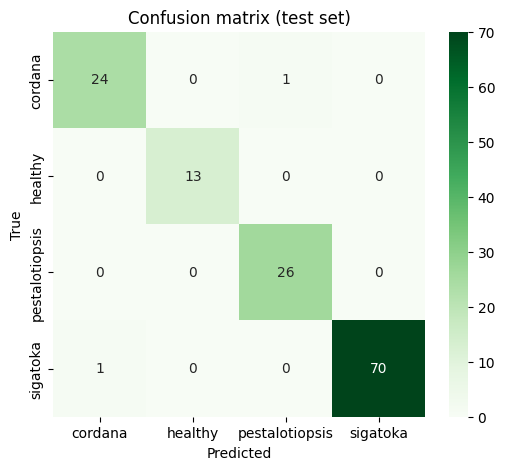

In [8]:
def predict_tta(ds):
    probs, ys = [], []
    for x, y, _ in ds:
        p = model.predict(x, verbose=0)
        p += model.predict(tf.image.flip_left_right(x), verbose=0)
        p += model.predict(tf.image.flip_up_down(x), verbose=0)
        probs.append(p / 3); ys.append(y.numpy())
    return np.concatenate(probs), np.concatenate(ys).argmax(1)

probs, y_true = predict_tta(test_ds)
y_pred = probs.argmax(1)

print("Test accuracy:", (y_pred == y_true).mean().round(4))
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)"); plt.show()

WRONG   | true=sigatoka        pred=cordana         conf=0.41 | top-2: cordana 0.41, pestalotiopsis 0.29 | 370.jpeg
WRONG   | true=cordana         pred=pestalotiopsis  conf=0.35 | top-2: pestalotiopsis 0.35, cordana 0.25 | 123.jpeg
CORRECT | true=healthy         pred=healthy         conf=0.44 | top-2: healthy 0.44, sigatoka 0.28 | 82.jpeg
CORRECT | true=sigatoka        pred=sigatoka        conf=0.49 | top-2: sigatoka 0.49, healthy 0.26 | 361.jpeg


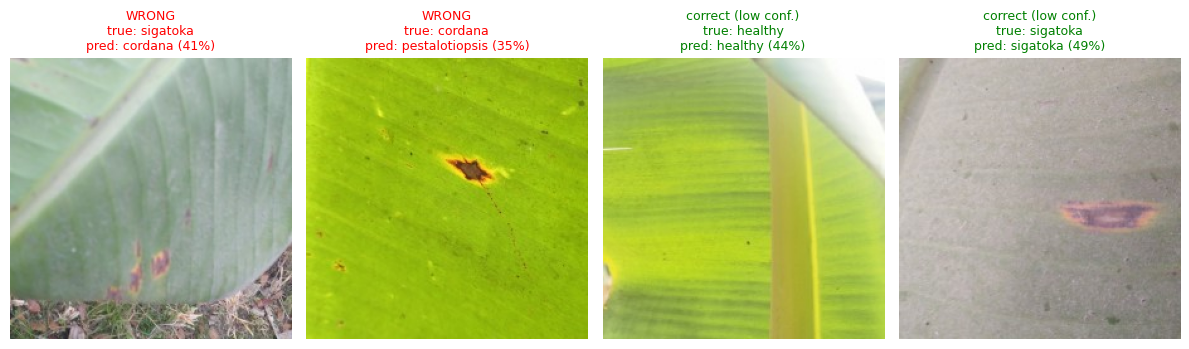

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import matplotlib.image as mpimg

conf  = probs.max(1)
wrong = np.where(y_pred != y_true)[0]
right = np.where(y_pred == y_true)[0]
extra = right[np.argsort(conf[right])][: max(0, 4 - len(wrong))]   # lowest-confidence CORRECT images
show  = list(wrong) + list(extra)

for i in show:
    top2 = np.argsort(probs[i])[::-1][:2]
    print(("WRONG  " if i in wrong else "CORRECT"),
          f"| true={CLASSES[y_true[i]]:15s} pred={CLASSES[y_pred[i]]:15s} conf={conf[i]:.2f}",
          "| top-2:", ", ".join(f"{CLASSES[j]} {probs[i][j]:.2f}" for j in top2),
          "|", os.path.basename(test_df.path.values[i]))

fig, ax = plt.subplots(1, len(show), figsize=(3.0 * len(show), 3.6))
for a, i in zip(np.atleast_1d(ax), show):
    bad = i in wrong
    a.imshow(mpimg.imread(test_df.path.values[i])); a.axis("off")
    a.set_title(f"{'WRONG' if bad else 'correct (low conf.)'}\ntrue: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]*100:.0f}%)",
                fontsize=9, color="red" if bad else "green")
plt.tight_layout(); plt.savefig("fig2_errors.png", dpi=250, bbox_inches="tight"); plt.show()
files.download("fig2_errors.png")

## 9. Save model & predict on your own leaf photo

In [9]:
model.save("banana_leaf_model.keras")
json.dump(CLASSES, open("classes.json", "w"))

def predict_image(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))[None]
    p = (model.predict(img, verbose=0) + model.predict(tf.image.flip_left_right(img), verbose=0)) / 2
    i = int(p.argmax())
    plt.imshow(img[0].numpy().astype("uint8")); plt.axis("off")
    plt.title(f"{CLASSES[i]} ({p[0][i]*100:.1f}%)"); plt.show()

# Try it:
# up = files.upload(); predict_image(list(up)[0])
# files.download("banana_leaf_model.keras")